Mounted at /content/drive
✓ Validación GroupKFold verificada: 0 pacientes compartidos entre Train y Validación.
✓ Archivo maestro guardado en: /content/drive/MyDrive/BaseDatos/df_procesado_folds.csv

--- PESOS DE PÉRDIDA POR CLASE ---
Clase N (n_train=2302): peso = 0.1093
Clase D (n_train=1287): peso = 0.1955
Clase G (n_train= 232): peso = 1.0843
Clase C (n_train= 230): peso = 1.0938
Clase A (n_train= 212): peso = 1.1866
Clase H (n_train= 101): peso = 2.4908
Clase M (n_train= 180): peso = 1.3976
Clase O (n_train= 569): peso = 0.4421


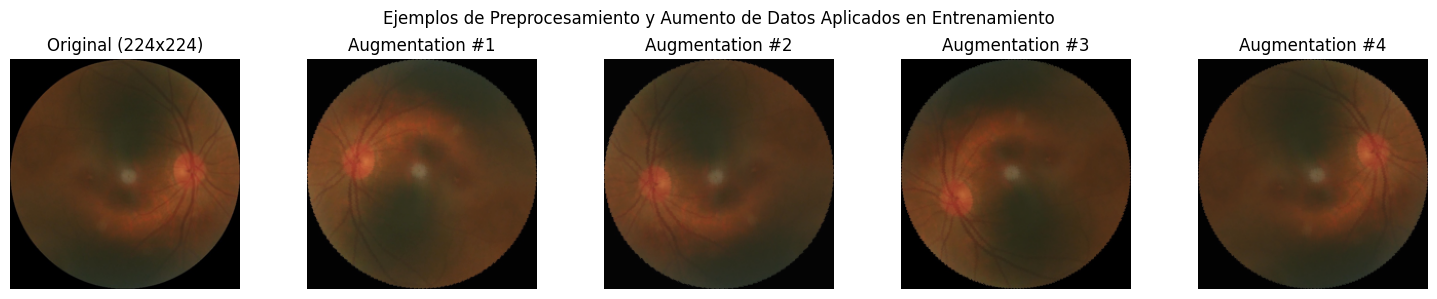

In [ ]:
# ==============================================================================
# CUADERNO 02: PREPROCESAMIENTO, PARTICIÓN SIN FUGA DE DATOS Y DATA AUGMENTATION
# ==============================================================================
from google.colab import drive
import os
import ast
import numpy as np
import pandas as pd
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

# 1. Montar Google Drive y cargar datos
drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/BaseDatos'
CSV_PATH = os.path.join(BASE_DIR, 'full_df.csv')
PREPROC_DIR = os.path.join(BASE_DIR, 'preprocessed_images')

df = pd.read_csv(CSV_PATH)
archivos_existentes = set(os.listdir(PREPROC_DIR))
df_clean = df[df['filename'].isin(archivos_existentes)].copy().reset_index(drop=True)

# 2. Codificación ordenada de las 8 clases
df_clean['clase'] = df_clean['labels'].apply(lambda x: ast.literal_eval(x)[0])
clases_ordenadas = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
clase_a_idx = {c: i for i, c in enumerate(clases_ordenadas)}
df_clean['label_idx'] = df_clean['clase'].map(clase_a_idx)

# 3. Validación Agrupada por Paciente (Prevención estricta de Data Leakage)
gkf = GroupKFold(n_splits=5)
df_clean['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(gkf.split(df_clean, df_clean['clase'], groups=df_clean['ID'])):
    df_clean.loc[val_idx, 'fold'] = fold

# Verificación matemática de 0 fuga de pacientes
pacientes_val = set(df_clean[df_clean['fold'] == 0]['ID'])
pacientes_train = set(df_clean[df_clean['fold'] != 0]['ID'])
assert len(pacientes_val.intersection(pacientes_train)) == 0, "¡ERROR: Fuga de pacientes detectada!"
print("✓ Validación GroupKFold verificada: 0 pacientes compartidos entre Train y Validación.")

# 4. Guardar dataset maestro procesado para los cuadernos de modelado (03, 04 y 05)
PROCESSED_CSV_PATH = os.path.join(BASE_DIR, 'df_procesado_folds.csv')
df_clean.to_csv(PROCESSED_CSV_PATH, index=False)
print(f"✓ Archivo maestro guardado en: {PROCESSED_CSV_PATH}")

# 5. Cálculo de pesos inversos por clase para mitigar desbalance
conteos = df_clean[df_clean['fold'] != 0]['label_idx'].value_counts().sort_index().values
pesos_clases = 1.0 / torch.tensor(conteos, dtype=torch.float32)
pesos_clases = pesos_clases / pesos_clases.sum() * len(clases_ordenadas)

print("\n--- PESOS DE PÉRDIDA POR CLASE ---")
for c, cnt, p in zip(clases_ordenadas, conteos, pesos_clases):
    print(f"Clase {c} (n_train={cnt:4d}): peso = {p:.4f}")

# 6. Visualización de Data Augmentation sobre una imagen de ejemplo
ejemplo_path = os.path.join(PREPROC_DIR, df_clean.iloc[0]['filename'])
img_orig = Image.open(ejemplo_path).convert('RGB')

aug_demo = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15)
])

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(img_orig.resize((224, 224)))
axes[0].set_title("Original (224x224)")
axes[0].axis('off')

for i in range(1, 5):
    axes[i].imshow(aug_demo(img_orig))
    axes[i].set_title(f"Augmentation #{i}")
    axes[i].axis('off')
plt.suptitle("Ejemplos de Preprocesamiento y Aumento de Datos Aplicados en Entrenamiento")
plt.tight_layout()
plt.show()